# MF 731 Homework 7, Part 2 - EVT risk measures for the S&P 500

Code only. Write-up and discussion are in `hw7_part2_written.ipynb`.

$V = \$1{,}000{,}000$ in the S&P 500 each day, linearized loss $L = -VX$.
$\text{VaR}_\alpha$ for $\alpha \in [0.99, 0.9999]$ by four methods: (1) empirical,
(2) normal with EWMA moments, (3) GEV block maxima with $n = 73$ and $n = 35$,
(4) GP excess losses over $u = \text{VaR}_{0.95}$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, genextreme, genpareto

V0 = 1_000_000
LAM = 0.97          # EWMA mean
THETA = 0.97        # EWMA variance
N_INIT = 100        # EWMA initialization period (days)
KD = 1000           # GEV / GPD fits are done in $ thousand

# 100 values of alpha in steps of 0.000099, ending at 0.9999 (sheet)
alphas = 0.99 + 0.000099 * np.arange(1, 101)

plt.rcParams['figure.figsize'] = (11, 5)


def var_emp(losses, a):
    # VaR from a sample: the ceil(n*a)-th order statistic
    ls = np.sort(np.asarray(losses))
    n = len(ls)
    return ls[int(np.ceil(n * a)) - 1]

### Data

In [2]:
# S&P 500 daily closes, saved to csv so this runs offline. To pull fresh data:
#     import yfinance as yf
#     yf.download('^GSPC', start='2011-11-01', end='2021-12-29')['Close']
# Yahoo has 2557 closes through 12/29/2021, one more than the sheet's
# N + 1 = 2556, so as the sheet says the end date is moved to 12/28/2021.
prices = pd.read_csv('sp500_daily.csv', parse_dates=['Date'])
prices = prices.set_index('Date')['SP500']

X = np.log(prices / prices.shift(1)).dropna()
x = X.values
N = len(x)
L = -V0 * x                          # linearized daily loss, $1M held each day

print('N + 1 =', len(prices), 'closes,',
      prices.index[0].date(), '->', prices.index[-1].date())
print('N =', N, 'log returns')
print('alpha grid: %d values, %.6f to %.6f' % (len(alphas), alphas[0], alphas[-1]))
print('largest loss %.2f on %s' % (L.max(), X.idxmin().date()))

N + 1 = 2556 closes, 2011-11-01 -> 2021-12-28
N = 2555 log returns
alpha grid: 100 values, 0.990099 to 0.999900
largest loss 127652.20 on 2020-03-16


### (1) Empirical distribution

In [3]:
var_1 = np.array([var_emp(L, a) for a in alphas])

# above alpha = (N-1)/N the order statistic is the largest loss
print('empirical VaR is the sample maximum for alpha > %.6f' % ((N - 1) / N))
print('VaR_0.9999 = %.2f' % var_1[-1])

empirical VaR is the sample maximum for alpha > 0.999609
VaR_0.9999 = 127652.20


### (2) Normal with EWMA mean and variance as of 11/01/2021

In [4]:
# initialize with the sample mean and variance of the first 100 returns,
# then run the recursions through the return on 11/01/2021
X_t = X.loc[:'2021-11-01']
x_t = X_t.values
mu = x_t[:N_INIT].mean()
s2 = x_t[:N_INIT].var(ddof=1)
for xi in x_t[N_INIT:]:
    s2 = THETA * s2 + (1 - THETA) * (xi - mu)**2      # uses the old mean
    mu = LAM * mu + (1 - LAM) * xi
sig = np.sqrt(s2)

print('returns used: %d (last %s)' % (len(x_t), X_t.index[-1].date()))
print('mu_{t+D} = %.6e   sigma_{t+D} = %.6e   (%.2f%% annualized)'
      % (mu, sig, 100 * sig * np.sqrt(252)))

# L = -V X ~ N(-V mu, V^2 sigma^2)
var_2 = -V0 * mu + V0 * sig * norm.ppf(alphas)
print('VaR_0.9999 = %.2f' % var_2[-1])

returns used: 2516 (last 2021-11-01)
mu_{t+D} = 1.210096e-03   sigma_{t+D} = 7.227070e-03   (11.47% annualized)
VaR_0.9999 = 25667.50


### (3) GEV, block maxima

`genextreme` uses the shape $c = -\xi$. The block maxima are fitted in
\$ thousand and the location and scale converted back to dollars. Fitting in
dollars makes scipy's optimizer stop at a wrong point ($\xi \approx 4$,
$\sigma \approx 1.5$) with a much lower likelihood; in \$ thousand it agrees
with an independent Nelder-Mead fit of the likelihood.

In [5]:
def gev_var(xi, mu_g, sig_g, n, a):
    # VaR of one daily loss when the n-day block maximum ~ GEV(xi, mu, sigma)
    return mu_g + sig_g / xi * ((-n * np.log(a))**(-xi) - 1)


gev = {}
for n in (73, 35):
    m = N // n
    maxima = L[:m * n].reshape(m, n).max(axis=1)        # block maxima of L
    c, loc, scale = genextreme.fit(maxima / KD)         # fit in $ thousand
    xi_g, mu_g, sig_g = -c, KD * loc, KD * scale        # back to dollars
    gev[n] = dict(m=m, xi=xi_g, mu=mu_g, sig=sig_g,
                  var=gev_var(xi_g, mu_g, sig_g, n, alphas))
    # check against scipy's own quantile: P[X <= x] = H(x)^(1/n)
    check = KD * genextreme.ppf(alphas**n, c, loc, scale)
    print('n = %d, m = %d blocks:  xi = %.4f   mu = %.2f   sigma = %.2f'
          % (n, m, xi_g, mu_g, sig_g))
    diff = np.abs(gev[n]['var'] - check).max()
    print('    VaR_0.9999 = %.2f   (max diff vs ppf %.1e)'
          % (gev[n]['var'][-1], diff))

n = 73, m = 35 blocks:  xi = 0.1815   mu = 20958.16   sigma = 8732.71
    VaR_0.9999 = 90352.51   (max diff vs ppf 5.8e-11)
n = 35, m = 73 blocks:  xi = 0.2141   mu = 15298.85   sigma = 8246.20
    VaR_0.9999 = 106042.15   (max diff vs ppf 2.0e-10)


### (4) GP distribution for losses above $u = \text{VaR}_{0.95}$

In [6]:
u = var_emp(L, 0.95)
excess = L[L > u] - u
F_u = 0.95                                      # by construction, as on the sheet

# fit in $ thousand (location fixed at 0) and scale beta back to dollars
c, loc, scale = genpareto.fit(excess / KD, floc=0)
xi_p, beta = c, KD * scale                      # genpareto's c is xi itself

var_4 = u + beta / xi_p * (((1 - F_u) / (1 - alphas))**xi_p - 1)

print('u = VaR_0.95 = %.2f   exceedances: %d   (1 - N_u/N = %.5f)'
      % (u, len(excess), 1 - len(excess) / N))
print('xi = %.4f   beta = %.2f' % (xi_p, beta))
print('VaR_0.9999 = %.2f' % var_4[-1])

u = VaR_0.95 = 15252.86   exceedances: 127   (1 - N_u/N = 0.95029)
xi = 0.2656   beta = 7594.30
VaR_0.9999 = 135610.18


### $\alpha = 0.9999$

In [7]:
methods = {
    '(1) empirical': var_1,
    '(2) normal EWMA': var_2,
    '(3) GEV n=73': gev[73]['var'],
    '(3) GEV n=35': gev[35]['var'],
    '(4) GPD': var_4,
}
assert abs(alphas[-1] - 0.9999) < 1e-12
table = pd.Series({k: v[-1] for k, v in methods.items()}, name='VaR_0.9999')
print(table.round(2).to_string())
print('\nhighest:', table.idxmax())
print('GPD / GEV(73) = %.3f   GPD / GEV(35) = %.3f   GEV(73) / GEV(35) = %.3f'
      % (var_4[-1] / gev[73]['var'][-1], var_4[-1] / gev[35]['var'][-1],
         gev[73]['var'][-1] / gev[35]['var'][-1]))

(1) empirical      127652.20
(2) normal EWMA     25667.50
(3) GEV n=73        90352.51
(3) GEV n=35       106042.15
(4) GPD            135610.18

highest: (4) GPD
GPD / GEV(73) = 1.501   GPD / GEV(35) = 1.279   GEV(73) / GEV(35) = 0.852


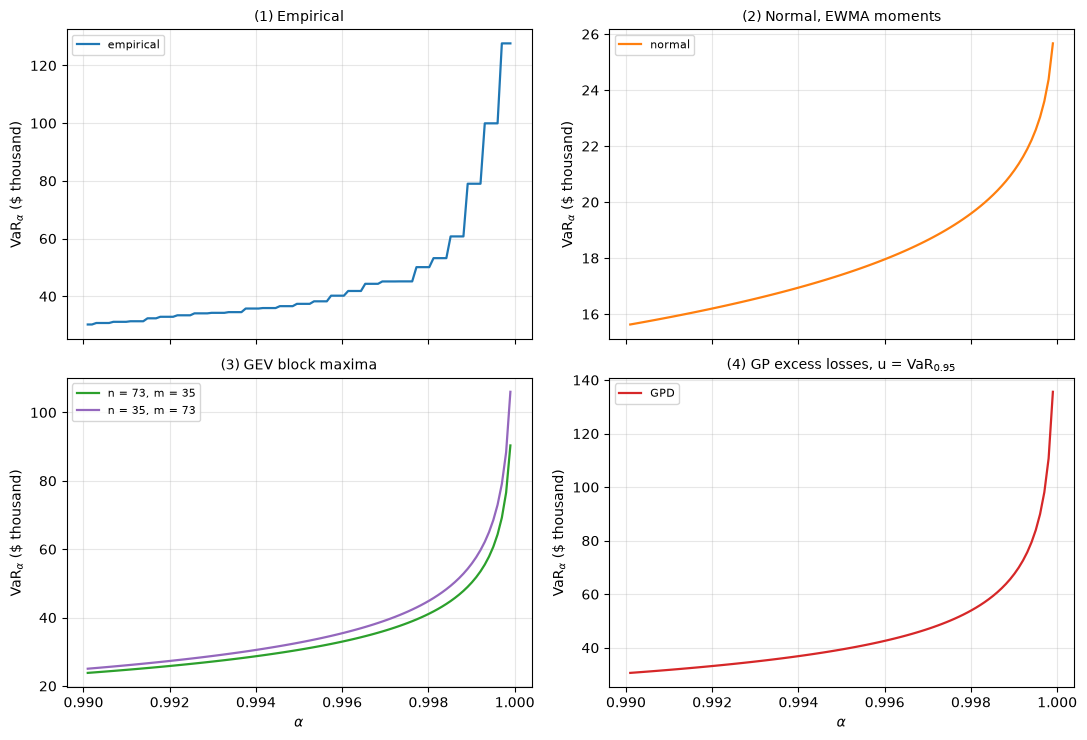

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
kd = 1000                                      # plot in $ thousand
panels = [
    (ax[0, 0], '(1) Empirical', [(var_1, 'C0', 'empirical')]),
    (ax[0, 1], '(2) Normal, EWMA moments', [(var_2, 'C1', 'normal')]),
    (ax[1, 0], '(3) GEV block maxima', [(gev[73]['var'], 'C2', 'n = 73, m = 35'),
                                        (gev[35]['var'], 'C4', 'n = 35, m = 73')]),
    (ax[1, 1], '(4) GP excess losses, u = VaR$_{0.95}$', [(var_4, 'C3', 'GPD')]),
]
for a_, title, curves in panels:
    for v, col, lab in curves:
        a_.plot(alphas, v / kd, color=col, lw=1.6, label=lab)
    a_.set_title(title, fontsize=10)
    a_.set_ylabel('VaR$_\\alpha$ (\\$ thousand)')
    a_.legend(fontsize=8)
    a_.grid(alpha=0.3)
for a_ in ax[1]:
    a_.set_xlabel('$\\alpha$')
fig.tight_layout()
plt.show()